In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración para que los gráficos se vean modernos y limpios
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Suprimir alertas de pandas innecesarias
import warnings
warnings.filterwarnings('ignore')

print("🚀 Entorno configurado y librerías cargadas con éxito.")


🚀 Entorno configurado y librerías cargadas con éxito.


In [52]:
import os
import pandas as pd

ruta_correcta = "../dataset/data.csv"

# Definición estricta de tipos de datos para optimizar la memoria RAM (Best Practice de DE)
schema_types = {
    'InvoiceNo': str,
    'StockCode': str,
    'Description': str,
    'Quantity': 'int32',       # int32 es más que suficiente para volúmenes transaccionales
    'UnitPrice': 'float32',    # float32 ahorra espacio frente a float64
    'CustomerID': str          # Lo leemos como texto inicialmente para evitar problemas con nulos
}

if os.path.exists(ruta_correcta):
    print("🎯 ¡Dataset encontrado! Iniciando carga optimizada...")
    # Cargamos aplicando el esquema y optimizando la lectura
    df = pd.read_csv(ruta_correcta, encoding="ISO-8859-1", dtype=schema_types)
    print(f"📊 Filas cargadas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
    print(f"💾 Uso de memoria optimizado: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
else:
    print("❌ No se encontró el archivo en la ruta especificada.")


🎯 ¡Dataset encontrado! Iniciando carga optimizada...
📊 Filas cargadas: 541,909 | Columnas: 8
💾 Uso de memoria optimizado: 65.14 MB


In [53]:
print("🔍 Conteo de valores nulos por columna:")
nulos = df.isnull().sum()
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
tabla_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos.round(2)})
print(tabla_nulos[tabla_nulos['Nulos'] > 0])

# --- TRATAMIENTO DE NULOS CORREGIDO ---
df['Description'] = df['Description'].fillna('UNKNOWN_ITEM')
df['CustomerID'] = df['CustomerID'].fillna(99999).astype(int)

print("\n✔️ Tratamiento de nulos completado. Verificación final:")
print(f"Nulos restantes en el dataset: {df.isnull().sum().sum()}")


🔍 Conteo de valores nulos por columna:
              Nulos  Porcentaje (%)
Description    1454            0.27
CustomerID   135080           24.93

✔️ Tratamiento de nulos completado. Verificación final:
Nulos restantes en el dataset: 0


In [54]:
duplicados_conteo = df.duplicated().sum()
print(f"👥 Se encontraron {duplicados_conteo} filas completamente duplicadas.")

if duplicados_conteo > 0:
    # Eliminar duplicados manteniendo la primera ocurrencia
    df = df.drop_duplicates(keep='first')
    print(f"✨ Duplicados eliminados. Nuevas dimensiones del dataset: {df.shape}")
else:
    print("📋 No se requirieron eliminaciones por duplicados.")


👥 Se encontraron 5268 filas completamente duplicadas.
✨ Duplicados eliminados. Nuevas dimensiones del dataset: (536641, 8)


In [55]:
print("⚙️ Iniciando limpieza analítica avanzada...")

# 1. Formateo de fechas robusto manejando estructuras mixtas de texto
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', errors='coerce')

# 2. Remover filas con fechas rotas si existieran
df = df.dropna(subset=['InvoiceDate'])

# 3. Filtrar outliers operativos: Cantidades y precios estrictamente mayores a cero
# Esto remueve registros de prueba con precio 0.0 que sesgan la demanda real
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# 4. Feature Engineering Avanzado
df['TotalRevenue'] = df['Quantity'] * df['UnitPrice']
df['Año'] = df['InvoiceDate'].dt.year
df['Mes'] = df['InvoiceDate'].dt.month
df['DiaSemana'] = df['InvoiceDate'].dt.day_name()
df['Hora'] = df['InvoiceDate'].dt.hour # Nueva dimensión para analizar picos de tráfico en bodega

print(f"🚀 Pipeline completado. Registros limpios para el modelo: {df.shape[0]:,}")


⚙️ Iniciando limpieza analítica avanzada...
🚀 Pipeline completado. Registros limpios para el modelo: 524,878


In [56]:
# Agrupamos por código de producto y descripción para conocer el Top 10 por ingresos
top_productos = df.groupby(['StockCode', 'Description']).agg(
    Unidades_Vendidas=('Quantity', 'sum'),
    Total_Ingresos=('TotalRevenue', 'sum'),
    Numero_Pedidos=('InvoiceNo', 'count')
).sort_values(by='Total_Ingresos', ascending=False).head(10).reset_index()

print("🏆 TOP 10 PRODUCTOS CON MAYOR FACTURACIÓN EN EL E-COMMERCE:")
print(top_productos)


🏆 TOP 10 PRODUCTOS CON MAYOR FACTURACIÓN EN EL E-COMMERCE:
  StockCode                         Description  Unidades_Vendidas  \
0       DOT                      DOTCOM POSTAGE                706   
1     22423            REGENCY CAKESTAND 3 TIER              13851   
2     23843         PAPER CRAFT , LITTLE BIRDIE              80995   
3    85123A  WHITE HANGING HEART T-LIGHT HOLDER              37580   
4     47566                       PARTY BUNTING              18283   
5    85099B             JUMBO BAG RED RETROSPOT              48371   
6     23166      MEDIUM CERAMIC TOP STORAGE JAR              78033   
7      POST                             POSTAGE               3150   
8         M                              Manual               6984   
9     23084                  RABBIT NIGHT LIGHT              30739   

   Total_Ingresos  Numero_Pedidos  
0   206248.770286             706  
1   174156.537665            2007  
2   168469.593821               1  
3   104284.239835         

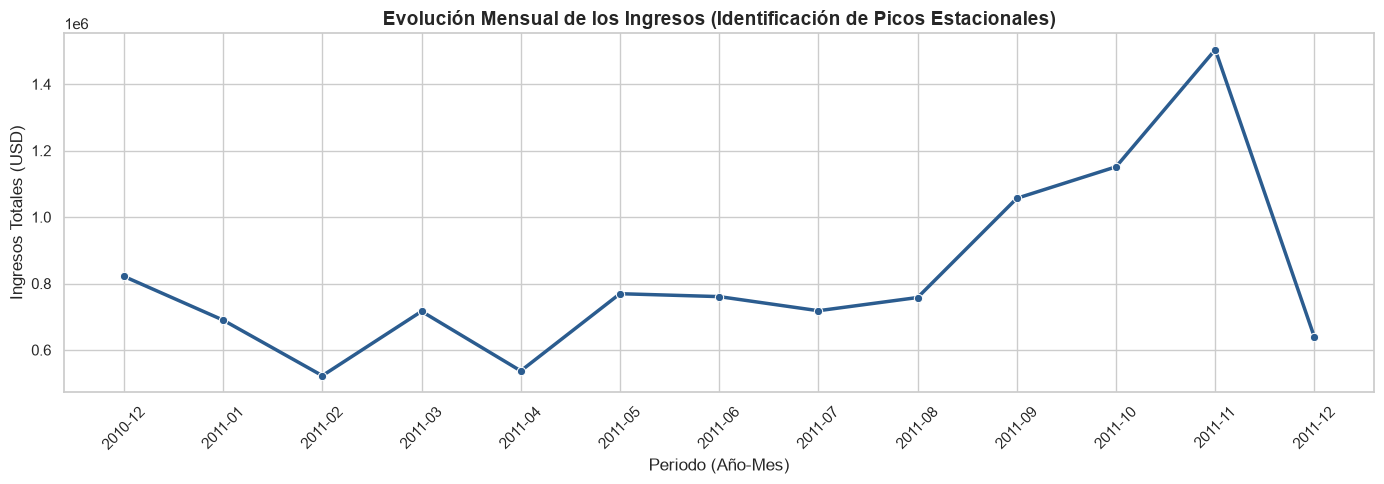

In [57]:
# Agrupamos los datos de manera cronológica por Año y Mes
ventas_mensuales = df.groupby(['Año', 'Mes'])['TotalRevenue'].sum().reset_index()
ventas_mensuales['Periodo'] = ventas_mensuales['Año'].astype(str) + "-" + ventas_mensuales['Mes'].astype(str).str.zfill(2)

# Crear gráfico de línea
plt.figure(figsize=(14, 5))
sns.lineplot(data=ventas_mensuales, x='Periodo', y='TotalRevenue', marker='o', color='#2b5c8f', linewidth=2.5)
plt.title('Evolución Mensual de los Ingresos (Identificación de Picos Estacionales)', fontsize=14, fontweight='bold')
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Ingresos Totales (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


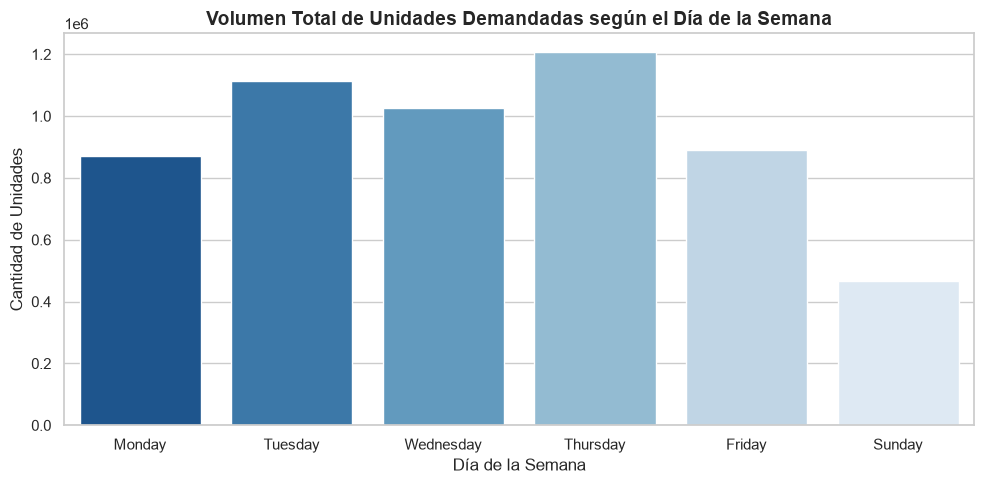

In [58]:
# Agrupamos por día de la semana para entender qué días procesa más carga la bodega logistica
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'] # Nota: Este dataset no suele tener registros los Sábados
demanda_diaria = df.groupby('DiaSemana')['Quantity'].sum().reindex(orden_dias).reset_index()

# Crear gráfico de barras
plt.figure(figsize=(10, 5))
sns.barplot(data=demanda_diaria, x='DiaSemana', y='Quantity', palette='Blues_r')
plt.title('Volumen Total de Unidades Demandadas según el Día de la Semana', fontsize=14, fontweight='bold')
plt.xlabel('Día de la Semana', fontsize=12)
plt.ylabel('Cantidad de Unidades', fontsize=12)
plt.tight_layout()
plt.show()
